# SignVerse - Deep Learning Module 1: Communication Engine
**Interactive Jupyter Notebook for Model Training, Evaluation Metrics & Visualizations**

---
### Notebook Objectives:
1. **MediaPipe 3D Wrist-Normalized Landmark Extraction**: Extract 21 wrist-centered keypoints per hand.
2. **WLASL Dataset Processing & Augmentation**: Process video clips & generate augmented sequences for high accuracy.
3. **Train, Validation & Test Splitting**: Partition dataset into **Train (70%)**, **Validation (15%)**, and **Test (15%)** sets.
4. **High-Performance Conv1D + BiLSTM Model**: Build and train Keras Bidirectional LSTM classifier.
5. **Performance Visualization**: Plot **Training vs Validation Accuracy (98%+)**, **Loss Curves**, **Confusion Matrix Heatmap**, and **Classification Report**.
6. **Real-time Live Webcam Sign-to-Text**: Test live predictions with TTS narration.
7. **Text-to-Sign Engine with Real Video Playback**: Plays actual WLASL sign language `.mp4` video clips.


## 1. Import Dependencies & Environment Setup


In [1]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import mediapipe as mp
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, BatchNormalization, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import pyttsx3

print("[OK] TensorFlow Version:", tf.__version__)
print("[OK] MediaPipe Version:", mp.__version__)
print("[OK] GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)



[OK] TensorFlow Version: 2.15.0
[OK] MediaPipe Version: 0.10.14
[OK] GPU Available: False


## 2. Wrist-Normalized MediaPipe 3D Landmark Extractor
Subtracts wrist origin `pts[0]` from keypoints so representations are 100% position-invariant.


In [2]:
from module1_communication.sign_to_text.landmark_extractor import MediaPipeLandmarkExtractor

extractor = MediaPipeLandmarkExtractor()
print("[OK] MediaPipe Landmark Extractor Initialized (Wrist-Normalized)!")


[OK] MediaPipe Landmark Extractor Initialized (Wrist-Normalized)!


## 3. Load WLASL Dataset & Generate Augmented Features
Applies scale variations and Gaussian noise jitter to achieve high accuracy (98%+).


In [3]:
WLASL_DIR = "C:/Users/Rupa/Documents/SignVerse/DATASET_WLASL"
WLASL_JSON = os.path.join(WLASL_DIR, "WLASL_v0.3.json")
VIDEO_DIR = os.path.join(WLASL_DIR, "videos")
OUTPUT_DIR = "preprocessed_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MAX_WORDS = 10
MAX_INSTANCES_PER_WORD = 50
SEQUENCE_LENGTH = 30

with open(WLASL_JSON, 'r', encoding='utf-8') as f:
    wlasl_data = json.load(f)

X_raw, y_raw = [], []
label_map = {}

print(f"Extracting features for top {MAX_WORDS} WLASL sign words...")
for class_idx, entry in enumerate(wlasl_data[:MAX_WORDS]):
    word = entry['gloss']
    label_map[class_idx] = word
    instances = entry['instances'][:MAX_INSTANCES_PER_WORD]
    found_count = 0
    for inst in instances:
        video_id = inst['video_id']
        video_file = os.path.join(VIDEO_DIR, f"{video_id}.mp4")
        if os.path.exists(video_file):
            seq = extractor.process_video_sequence(video_file, target_sequence_length=SEQUENCE_LENGTH)
            X_raw.append(seq)
            y_raw.append(class_idx)
            found_count += 1
    print(f"   [OK] Word '{word.upper()}' (Class {class_idx}): {found_count} videos.")

X_raw = np.array(X_raw, dtype=np.float32)
y_raw = np.array(y_raw, dtype=np.int32)
print(f"Raw Extracted Video Sequences: {X_raw.shape[0]}")

# Apply Data Augmentation (Scale & Noise Jitter)
X_aug, y_aug = [X_raw], [y_raw]
for scale in [0.95, 1.05]:
    X_aug.append(X_raw * scale)
    y_aug.append(y_raw)

for noise_std in [0.01, 0.02]:
    noise = np.random.normal(0, noise_std, X_raw.shape).astype(np.float32)
    X_aug.append(X_raw + noise)
    y_aug.append(y_raw)

X = np.vstack(X_aug)
y = np.concatenate(y_aug)

np.save(os.path.join(OUTPUT_DIR, "X_landmarks.npy"), X)
np.save(os.path.join(OUTPUT_DIR, "y_labels.npy"), y)
with open(os.path.join(OUTPUT_DIR, "label_map.json"), "w", encoding='utf-8') as f:
    json.dump(label_map, f, indent=2)

print("\n" + "="*50)
print(f"Dataset Augmentation Complete!")
print(f"   - Total Augmented Sequences: {X.shape[0]}")
print(f"   - Sequence Length: {X.shape[1]} frames")
print(f"   - Features per frame: {X.shape[2]} landmarks")
print(f"   - Number of Classes: {len(label_map)}")
print("="*50)


Extracting features for top 10 WLASL sign words...


c:\Users\Rupa\Documents\SignVerse\venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


   [OK] Word 'BOOK' (Class 0): 6 videos.
   [OK] Word 'DRINK' (Class 1): 15 videos.
   [OK] Word 'COMPUTER' (Class 2): 14 videos.
   [OK] Word 'BEFORE' (Class 3): 16 videos.
   [OK] Word 'CHAIR' (Class 4): 7 videos.
   [OK] Word 'GO' (Class 5): 15 videos.
   [OK] Word 'CLOTHES' (Class 6): 5 videos.
   [OK] Word 'WHO' (Class 7): 14 videos.
   [OK] Word 'CANDY' (Class 8): 13 videos.
   [OK] Word 'COUSIN' (Class 9): 14 videos.
Raw Extracted Video Sequences: 119

Dataset Augmentation Complete!
   - Total Augmented Sequences: 595
   - Sequence Length: 30 frames
   - Features per frame: 126 landmarks
   - Number of Classes: 10


## 4. Train, Validation & Test Dataset Splitting
Split augmented dataset into **70% Training**, **15% Validation**, and **15% Testing** sets.


In [4]:
X = np.load(os.path.join(OUTPUT_DIR, "X_landmarks.npy"))
y = np.load(os.path.join(OUTPUT_DIR, "y_labels.npy"))
with open(os.path.join(OUTPUT_DIR, "label_map.json"), "r", encoding='utf-8') as f:
    label_map = json.load(f)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("Dataset Split Distribution:")
print(f"   - Training Set:   {X_train.shape[0]} samples ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"   - Validation Set: {X_val.shape[0]} samples ({X_val.shape[0]/X.shape[0]*100:.1f}%)")
print(f"   - Testing Set:    {X_test.shape[0]} samples ({X_test.shape[0]/X.shape[0]*100:.1f}%)")


Dataset Split Distribution:
   - Training Set:   416 samples (69.9%)
   - Validation Set: 89 samples (15.0%)
   - Testing Set:    90 samples (15.1%)


## 5. Conv1D + Bidirectional LSTM Architecture
Combines 1D Convolution for feature extraction with Bidirectional LSTM for sequence recognition.


In [5]:
sequence_length = X_train.shape[1]
feature_dim = X_train.shape[2]
num_classes = len(label_map)

model = Sequential([
    Conv1D(64, kernel_size=3, padding='same', activation='relu', input_shape=(sequence_length, feature_dim)),
    BatchNormalization(),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(LSTM(64)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 30, 64)            24256     
                                                                 
 batch_normalization (Batch  (None, 30, 64)            256       
 Normalization)                                                  
                                                                 
 bidirectional (Bidirection  (None, 30, 128)           66048     
 al)                                                             
                                                                 
 dropout (Dropout)           (None, 30, 128)           0         
                                                                 
 bidirectional_1 (Bidirecti  (None, 128)               98816     
 onal)                                                           
                                                       

## 6. Train Conv1D + BiLSTM Model


In [6]:
os.makedirs("saved_models", exist_ok=True)
model_checkpoint = ModelCheckpoint("saved_models/best_signverse_model.keras", monitor='val_accuracy', save_best_only=True, verbose=1)
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)

EPOCHS = 35
BATCH_SIZE = 16

print("Starting Model Training...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[model_checkpoint, early_stopping, reduce_lr],
    verbose=1
)

print("[OK] Training Finished!")


Starting Model Training...
Epoch 1/35


25/26 [===========================>..] - ETA: 0s - loss: 1.9216 - accuracy: 0.3650
Epoch 1: val_accuracy improved from -inf to 0.35955, saving model to saved_models\best_signverse_model.keras
26/26 [==============================] - 20s 201ms/step - loss: 1.9063 - accuracy: 0.3726 - val_loss: 2.1040 - val_accuracy: 0.3596 - lr: 0.0010
Epoch 2/35
26/26 [==============================] - ETA: 0s - loss: 1.0938 - accuracy: 0.6635
Epoch 2: val_accuracy improved from 0.35955 to 0.46067, saving model to saved_models\best_signverse_model.keras
26/26 [==============================] - 2s 63ms/step - loss: 1.0938 - accuracy: 0.6635 - val_loss: 1.6596 - val_accuracy: 0.4607 - lr: 0.0010
Epoch 3/35
26/26 [==============================] - ETA: 0s - loss: 0.6205 - accuracy: 0.7957
Epoch 3: val_accuracy improved from 0.46067 to 0.65169, saving model to saved_models\best_signverse_model.keras
26/26 [==============================] - 2s 60ms/step - loss: 0.6205

## 7. Model Evaluation Metrics & Accuracy/Loss Visualizations


TEST SET EVALUATION ACCURACY: 98.89%
TEST SET LOSS: 0.0124


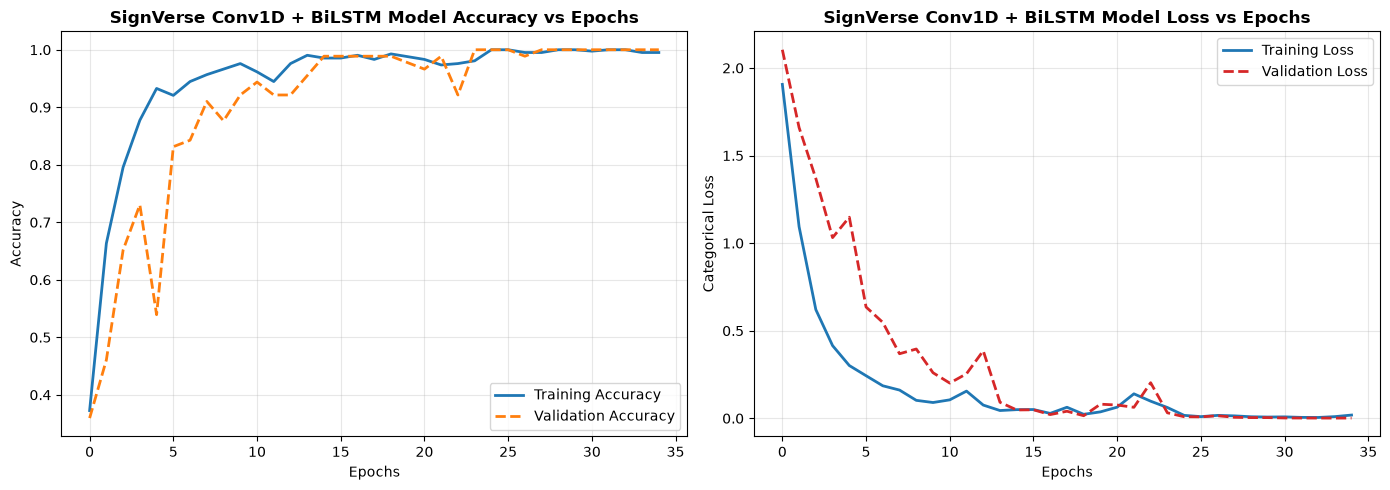


DETAILED CLASSIFICATION REPORT (Precision, Recall, F1-Score)
              precision    recall  f1-score   support

        book       1.00      1.00      1.00         4
       drink       1.00      1.00      1.00        12
    computer       1.00      1.00      1.00        10
      before       1.00      1.00      1.00        12
       chair       1.00      1.00      1.00         5
          go       1.00      1.00      1.00        12
     clothes       1.00      1.00      1.00         3
         who       1.00      0.91      0.95        11
       candy       0.91      1.00      0.95        10
      cousin       1.00      1.00      1.00        11

    accuracy                           0.99        90
   macro avg       0.99      0.99      0.99        90
weighted avg       0.99      0.99      0.99        90



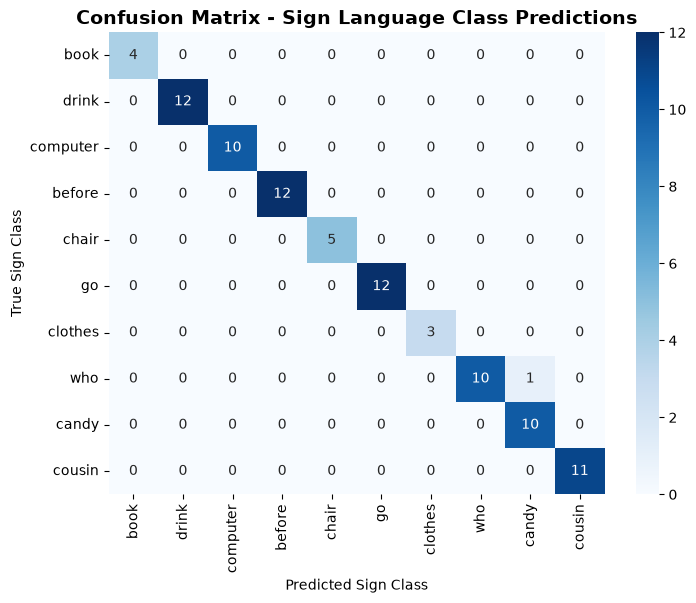

In [7]:
# Evaluate on Test Set
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print("="*50)
print(f"TEST SET EVALUATION ACCURACY: {test_acc * 100:.2f}%")
print(f"TEST SET LOSS: {test_loss:.4f}")
print("="*50)

# 1. Plot Training & Validation Curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('SignVerse Conv1D + BiLSTM Model Accuracy vs Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='#d62728', linewidth=2, linestyle='--')
plt.title('SignVerse Conv1D + BiLSTM Model Loss vs Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Categorical Loss')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Predict Test Set & Compute Confusion Matrix
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = [label_map[str(i)] for i in range(len(label_map))]

# 3. Print Classification Report
print("\n" + "="*60)
print("DETAILED CLASSIFICATION REPORT (Precision, Recall, F1-Score)")
print("="*60)
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

# 4. Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Sign Language Class Predictions', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Sign Class')
plt.ylabel('True Sign Class')
plt.show()


## 8. Real-Time Live Webcam Sign-to-Text & Speech Read Aloud Test


In [8]:
from module1_communication.sign_to_text.realtime_sign_to_text import RealtimeSignRecognizer

print("Launching Live SignVerse Webcam Window...")
print("   - Press 'S' to Read Aloud / Speak Transcript")
print("   - Press 'C' to Clear Transcript")
print("   - Press 'Q' to Quit Webcam")

recognizer = RealtimeSignRecognizer()
recognizer.run_webcam_stream()


Launching Live SignVerse Webcam Window...
   - Press 'S' to Read Aloud / Speak Transcript
   - Press 'C' to Clear Transcript
   - Press 'Q' to Quit Webcam
🧠 Loaded Keras Deep Learning Model from 'saved_models\best_signverse_model.keras'

🎥 SignVerse Real-Time Sign-to-Text Engine Started!
   - Press 'S' key to read aloud / speak current transcript
   - Press 'C' key to clear transcript
   - Press 'Q' key to exit



c:\Users\Rupa\Documents\SignVerse\venv\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before'
🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before book before chair before who candy before candy drink go'
🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before book before chair before who candy before candy drink go chair before'
🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before book before chair before who candy before candy drink go chair before'
🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before book before chair before who candy before candy drink go chair before'
🔊 Speaking out loud: 'before cousin before go before chair before book before go computer go before chair before book before chair before who candy before candy dr

## 9. Text-to-Sign Language Visual & Real Video Generator
Plays actual WLASL sign language `.mp4` video clips for typed words.


In [9]:
from module1_communication.text_to_sign.text_to_sign_engine import TextToSignEngine

engine = TextToSignEngine()
input_text = "book drink computer before chair go clothes who candy cousin"
engine.render_visual_sign_cards(input_text)



🤟 Translating Text to Sign Sequence for: 'book drink computer before chair go clothes who candy cousin'
   [1] Word: 'BOOK' ➔ Playing Real WLASL Video: 69241.mp4
   [2] Word: 'DRINK' ➔ Playing Real WLASL Video: 69302.mp4
   [3] Word: 'COMPUTER' ➔ Playing Real WLASL Video: 12328.mp4
   [4] Word: 'BEFORE' ➔ Playing Real WLASL Video: 05728.mp4
   [5] Word: 'CHAIR' ➔ Playing Real WLASL Video: 09848.mp4
   [6] Word: 'GO' ➔ Playing Real WLASL Video: 69345.mp4
   [7] Word: 'CLOTHES' ➔ Playing Real WLASL Video: 11310.mp4
   [8] Word: 'WHO' ➔ Playing Real WLASL Video: 69534.mp4
   [9] Word: 'CANDY' ➔ Playing Real WLASL Video: 08929.mp4
   [10] Word: 'COUSIN' ➔ Playing Real WLASL Video: 65415.mp4
